# Titanic Passenger Survival Prediction System

## Deployment Link:
Add your live deployment link here

This notebook builds a Titanic passenger survival prediction system using the same general workflow as the Heart Disease Prediction notebook.

## Setup: Running This Notebook From Scratch

In [1]:
%pip install numpy pandas scikit-learn prettytable matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## Step 1: Import Libraries

In [2]:
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2: Load Sample Data

In [3]:
sample_data = pd.read_csv("sample-data.csv")

print("\n\nSample Data:")
print("============\n")

pd.set_option("display.max_rows", None, "display.max_columns", None)
print(sample_data)



Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton       No
19  

## Step 3: Understand and Pre-process Sample Data

### Step 3.1: Understand Sample Data

In [4]:
print("\n\nAttributes in Sample Data:")
print("==========================\n")

print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["PClass"].count())
print("========================================\n")

print("\nMissing Values:")
print(sample_data.isnull().sum())



Attributes in Sample Data:

Index(['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived'], dtype='str')


Number of Instances in Sample Data: 100


Missing Values:
PClass      0
Gender      0
Sibling     0
Embarked    0
Survived    0
dtype: int64


### Step 3.2: Pre-process Sample Data

In [5]:
required_columns = ["PClass", "Gender", "Sibling", "Embarked", "Survived"]
sample_data = sample_data[required_columns].dropna().copy()

print("\n\nPre-processed Sample Data:")
print("==========================\n")
print(sample_data)



Pre-processed Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton

## Step 4: Feature Extraction

In [6]:
features = ["PClass", "Gender", "Sibling", "Embarked"]

sample_data_features = sample_data[features]
sample_data_output = sample_data["Survived"]

print("\n\nSelected Features:")
print("==================\n")
print(sample_data_features)

print("\n\nOutput:")
print("=======\n")
print(sample_data_output)



Selected Features:

    PClass  Gender Sibling     Embarked
0    Third    Male     One  Southampton
1   Second  Female    Zero  Southampton
2    Third    Male    Zero  Southampton
3    Third  Female   Three  Southampton
4    Third    Male    Zero   Queenstown
5    First  Female   Three  Southampton
6    Third    Male    Zero  Southampton
7    Third    Male    Zero  Southampton
8    First    Male    Zero  Southampton
9   Second    Male    Zero  Southampton
10   Third    Male     One   Queenstown
11   First    Male    Zero    Cherbourg
12   First    Male    Zero    Cherbourg
13  Second  Female    Zero  Southampton
14  Second    Male    Zero  Southampton
15   Third    Male     One    Cherbourg
16   Third    Male     Two    Cherbourg
17   Third    Male    Zero  Southampton
18   Third    Male    Zero  Southampton
19   Third  Female     One    Cherbourg
20   Third    Male    Zero    Cherbourg
21   First  Female    Zero  Southampton
22   First    Male    Zero    Cherbourg
23  Second  Female

## Step 5: Label Encoding the Sample Data

### Step 5.1: Train the Label Encoders

In [7]:
pclass_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
sibling_label_encoder = LabelEncoder()
embarked_label_encoder = LabelEncoder()
survived_label_encoder = LabelEncoder()

pclass_label_encoder.fit(sample_data["PClass"])
gender_label_encoder.fit(sample_data["Gender"])
sibling_label_encoder.fit(sample_data["Sibling"])
embarked_label_encoder.fit(sample_data["Embarked"])
survived_label_encoder.fit(sample_data["Survived"])

print("Label encoders trained.")
print("PClass categories:", list(pclass_label_encoder.classes_))
print("Gender categories:", list(gender_label_encoder.classes_))
print("Sibling categories:", list(sibling_label_encoder.classes_))
print("Embarked categories:", list(embarked_label_encoder.classes_))
print("Survived categories:", list(survived_label_encoder.classes_))

Label encoders trained.
PClass categories: ['First', 'Second', 'Third']
Gender categories: ['Female', 'Male']
Sibling categories: ['One', 'Three', 'Two', 'Zero']
Embarked categories: ['Cherbourg', 'Queenstown', 'Southampton']
Survived categories: ['No', 'Yes']


### Step 5.2: Label Encode the Output

In [8]:
sample_data_encoded = sample_data.copy()
sample_data_encoded["Survived"] = survived_label_encoder.transform(sample_data["Survived"])

print("\n\nSurvived Attribute After Label Encoding:")
print("========================================\n")
print(sample_data[["Survived"]].assign(
    encoded_survived=sample_data_encoded["Survived"].values
))

print("\nEncoded Target Counts:")
print(sample_data_encoded["Survived"].value_counts().sort_index())



Survived Attribute After Label Encoding:

   Survived  encoded_survived
0        No                 0
1       Yes                 1
2        No                 0
3       Yes                 1
4        No                 0
5       Yes                 1
6        No                 0
7       Yes                 1
8        No                 0
9       Yes                 1
10       No                 0
11      Yes                 1
12       No                 0
13      Yes                 1
14       No                 0
15      Yes                 1
16       No                 0
17      Yes                 1
18       No                 0
19      Yes                 1
20       No                 0
21      Yes                 1
22       No                 0
23      Yes                 1
24       No                 0
25      Yes                 1
26       No                 0
27      Yes                 1
28       No                 0
29      Yes                 1
30       No               

### Step 5.3: Label Encode the Input

In [9]:
sample_data_encoded["PClass"] = pclass_label_encoder.transform(sample_data["PClass"])
sample_data_encoded["Gender"] = gender_label_encoder.transform(sample_data["Gender"])
sample_data_encoded["Sibling"] = sibling_label_encoder.transform(sample_data["Sibling"])
sample_data_encoded["Embarked"] = embarked_label_encoder.transform(sample_data["Embarked"])

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

sample_data_encoded.to_csv("sample-data-encoded.csv", index=False)
print("\nSaved: sample-data-encoded.csv")



Sample Data after Label Encoding:

    PClass  Gender  Sibling  Embarked  Survived
0        2       1        0         2         0
1        1       0        3         2         1
2        2       1        3         2         0
3        2       0        1         2         1
4        2       1        3         1         0
5        0       0        1         2         1
6        2       1        3         2         0
7        2       1        3         2         1
8        0       1        3         2         0
9        1       1        3         2         1
10       2       1        0         1         0
11       0       1        3         0         1
12       0       1        3         0         0
13       1       0        3         2         1
14       1       1        3         2         0
15       2       1        0         0         1
16       2       1        2         0         0
17       2       1        3         2         1
18       2       1        3         2         0
19 

## Step 6: Execute the Training Phase

### Step 6.1: Split Sample Data into Training Data and Testing Data

In [10]:
training_data, testing_data = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

training_data.to_csv("training-data-encoded.csv", index=False)
testing_data.to_csv("testing-data-encoded.csv", index=False)

print("Training Data shape:", training_data.shape)
print("Testing Data shape:", testing_data.shape)

print("\nTraining Data:")
print(training_data)

print("\nTesting Data:")
print(testing_data)

Training Data shape: (80, 5)
Testing Data shape: (20, 5)

Training Data:
    PClass  Gender  Sibling  Embarked  Survived
0        2       1        0         2         0
1        1       0        3         2         1
2        2       1        3         2         0
3        2       0        1         2         1
4        2       1        3         1         0
5        0       0        1         2         1
6        2       1        3         2         0
7        2       1        3         2         1
8        0       1        3         2         0
9        1       1        3         2         1
10       2       1        0         1         0
11       0       1        3         0         1
12       0       1        3         0         0
13       1       0        3         2         1
14       1       1        3         2         0
15       2       1        0         0         1
16       2       1        2         0         0
17       2       1        3         2         1
18       2     

### Step 6.2: Split Input Vectors and Labels of Training Data

In [11]:
input_vector_train = training_data[features]
output_label_train = training_data["Survived"]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (80, 4)
Output labels (train) shape: (80,)


### Step 6.3: Train the Support Vector Classifier

In [12]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [13]:
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
print("Saved: svc_trained_model.pkl")

Saved: svc_trained_model.pkl


## Step 7: Execute the Testing Phase

### Step 7.1: Split Input Vectors and Labels of Testing Data

In [14]:
input_vector_test = testing_data[features]
output_label_test = testing_data["Survived"]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (20, 4)
Output labels (test) shape: (20,)


### Step 7.2: Load the Saved Model

In [15]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 7.3: Make Predictions on Testing Data

In [16]:
model_predictions = model.predict(input_vector_test)

testing_results = testing_data.copy()
testing_results["Predictions"] = model_predictions
testing_results.to_csv("model-predictions.csv", index=False)

print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(testing_results)



Predictions Returned by svc_trained_model:

    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3         2         1            1
82       2       1        3         2         0            0
83       0       1        0         2         1            0
84       1       1        3         2         0            0
85       2       0        0         1         1            1
86       1       1        3         2         0            0
87       0       0        0         2         1            1
88       2       1        3         2         0            0
89       1       0        3         2         1            1
90       1       1        3         2         0            0
91       1       0        3         2         1            1
92       2       1        3         0         0            0
93       0       1        0         2         1            0
94       0       1        0         2  

### Step 7.4: Calculate the Accuracy Score

In [17]:
model_accuracy_score = accuracy_score(
    testing_results["Survived"],
    testing_results["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


### Step 7.5: Detailed Evaluation Metrics


Classification Report:

                  precision    recall  f1-score   support

Not Survived (0)       0.71      1.00      0.83        10
    Survived (1)       1.00      0.60      0.75        10

        accuracy                           0.80        20
       macro avg       0.86      0.80      0.79        20
    weighted avg       0.86      0.80      0.79        20


Confusion Matrix:

                      Predicted: Not Survived  Predicted: Survived
Actual: Not Survived                       10                    0
Actual: Survived                            4                    6


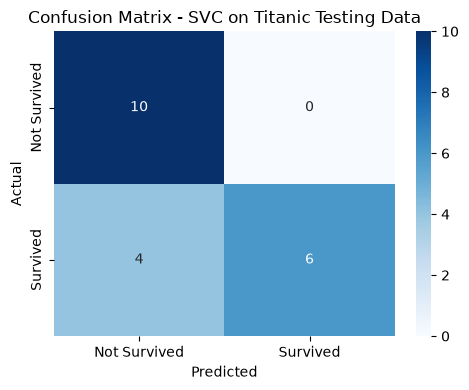

In [18]:
print("\nClassification Report:")
print("=======================\n")

print(classification_report(
    testing_results["Survived"],
    testing_results["Predictions"],
    labels=[0, 1],
    target_names=["Not Survived (0)", "Survived (1)"],
    zero_division=0
))

conf_matrix = confusion_matrix(
    testing_results["Survived"],
    testing_results["Predictions"],
    labels=[0, 1]
)

conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: Not Survived", "Actual: Survived"],
    columns=["Predicted: Not Survived", "Predicted: Survived"]
)

print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Titanic Testing Data")
plt.tight_layout()
plt.show()

## Step 8: Execute the Application Phase

### Step 8.1: Take Input from User

In [19]:
pclass_input = "First"
gender_input = "Male"
sibling_input = "Zero"
embarked_input = "Queenstown"

print(f"PClass: {pclass_input}")
print(f"Gender: {gender_input}")
print(f"Sibling: {sibling_input}")
print(f"Embarked: {embarked_input}")

PClass: First
Gender: Male
Sibling: Zero
Embarked: Queenstown


### Step 8.2: Convert User Input into Feature Vector

In [20]:
user_input = pd.DataFrame({
    "PClass": [pclass_input],
    "Gender": [gender_input],
    "Sibling": [sibling_input],
    "Embarked": [embarked_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

  PClass Gender Sibling    Embarked
0  First   Male    Zero  Queenstown


### Step 8.3: Label Encode the User Input

In [21]:
unseen_data_features = pd.DataFrame({
    "PClass": pclass_label_encoder.transform(user_input["PClass"]),
    "Gender": gender_label_encoder.transform(user_input["Gender"]),
    "Sibling": sibling_label_encoder.transform(user_input["Sibling"]),
    "Embarked": embarked_label_encoder.transform(user_input["Embarked"])
})

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   PClass  Gender  Sibling  Embarked
0       0       1        3         1


### Step 8.4: Load the Saved Model

In [22]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
print("Model loaded from svc_trained_model.pkl")

Model loaded from svc_trained_model.pkl


### Step 8.5: Model Prediction

In [23]:
predicted_survival = model.predict(unseen_data_features)

if predicted_survival[0] == 1:
    prediction = "SURVIVED"
else:
    prediction = "NOT SURVIVED"

pretty_table = PrettyTable()
pretty_table.add_column("Prediction", [prediction])

print(pretty_table)

+------------+
| Prediction |
+------------+
|  SURVIVED  |
+------------+


## Step 9: Execute the Feedback Phase

### Step 9.1: Collect Feedback

In [24]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert", "Student Tester", "Student Tester"],
    "Case": [
        "Passenger in first class",
        "Passenger with a different gender",
        "Passenger travelling with family"
    ],
    "Feedback": [
        "Compare model predictions with known historical outcomes.",
        "Test additional passengers to assess model behavior.",
        "Review whether the sample dataset represents different passenger groups."
    ]
})

print(example_feedback.to_string(index=False))

      Reviewer                              Case                                                                 Feedback
 Domain Expert          Passenger in first class                Compare model predictions with known historical outcomes.
Student Tester Passenger with a different gender                     Test additional passengers to assess model behavior.
Student Tester  Passenger travelling with family Review whether the sample dataset represents different passenger groups.


### Step 9.2: Make a List of Potential Improvements

In [25]:
improvements = [
    "Use a larger Titanic dataset",
    "Include additional features such as age and fare",
    "Evaluate the model with cross-validation",
    "Compare SVC with other classification models",
    "Tune model hyperparameters"
]

for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Use a larger Titanic dataset
2. Include additional features such as age and fare
3. Evaluate the model with cross-validation
4. Compare SVC with other classification models
5. Tune model hyperparameters


### Step 9.3: Improve the Model Based on Feedback

In [26]:
print("Next version: test additional features and compare model performance before replacing the saved model.")

Next version: test additional features and compare model performance before replacing the saved model.


## Step 10: Deploy Your Model as a Public Web App

The trained model is saved as `svc_trained_model.pkl`.

For deployment, keep the model file, application code, and required dataset files together in your project. Add your live deployment URL at the top of this notebook after deployment.

## Conclusion

This notebook builds a Titanic Passenger Survival Prediction System using a Support Vector Classifier. It loads and explores the dataset, preprocesses categorical values with label encoding, separates training and testing data, trains and saves the model, evaluates its predictions, and predicts survival for a new passenger input.